# Chapter 16 — 정오탐 분석과 탐지 개선 (실습)



In [ ]:
# 파트별 노트북은 같은 종류의 공통 데이터·모델 작업 폴더를 사용합니다.
from pathlib import Path as _BookPath
import os as _book_os
_book_cwd = _BookPath.cwd()
if (_book_cwd.name in {"part1", "part2", "part3", "part4"}
        and _book_cwd.parent.name in {"instructor", "exercises", "solutions"}):
    _book_os.chdir(_book_cwd.parent)


In [1]:
# === 한글 폰트 설정 (matplotlib) ===
from pathlib import Path
import matplotlib
from matplotlib import font_manager
for fp in ['/usr/share/fonts/truetype/nanum/NanumGothic.ttf',
           '/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf']:
    if Path(fp).exists():
        font_manager.fontManager.addfont(fp)
        matplotlib.rcParams['font.family'] = font_manager.FontProperties(fname=fp).get_name()
        break
matplotlib.rcParams['axes.unicode_minus'] = False

In [2]:
# 첫 사용시에만 주석 해제하여 실행 (Colab/venv 환경에 따라 일부는 이미 설치됨)
# !pip install -q pandas
# !pip install -q numpy
# !pip install -q matplotlib
# !pip install -q scipy
# !pip install -q scikit-learn

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix
rng = np.random.default_rng(42)

# 데이터 — ch09~11 형식
def gen(n, label, dur, pkts, syn):
    return pd.DataFrame({
        'log_dur':  np.log1p(rng.uniform(*dur, size=n)),
        'log_pkts': np.log1p(rng.integers(*pkts, size=n)),
        'syn':      rng.uniform(*syn, size=n),
        'label':    label,
    })
df = pd.concat([
    gen(16000,'BENIGN',(1000,1_000_000),(5,100),(0,0.05)),
    gen( 2300,'ATTACK',(10,5000),(500,5000),(0.4,0.7)),
], ignore_index=True).sample(frac=1, random_state=0).reset_index(drop=True)
df['y'] = (df['label']=='ATTACK').astype(int)

# --- 현실화: 정상/공격 경계 중첩 (정오탐이 실제로 존재해야 이 챕터가 의미가 있다) ---
_atk = df.index[df['y']==1].to_numpy()
_b1 = rng.choice(_atk, size=int(len(_atk)*0.25), replace=False)   # 공격 25%: 정상처럼(낮은 syn·pkts)
df.loc[_b1,'syn']      = rng.uniform(0, 0.1, size=len(_b1))
df.loc[_b1,'log_pkts'] = np.log1p(rng.integers(5, 150, size=len(_b1)))
_nrm = df.index[df['y']==0].to_numpy()
_b2 = rng.choice(_nrm, size=int(len(_nrm)*0.10), replace=False)   # 정상 10%: 공격처럼(높은 syn)
df.loc[_b2,'syn']      = rng.uniform(0.35, 0.7, size=len(_b2))
_flip = rng.choice(df.index.to_numpy(), size=int(len(df)*0.04), replace=False)  # 라벨 노이즈 4%
df.loc[_flip,'y'] = 1 - df.loc[_flip,'y']

X_tr, X_te, y_tr, y_te = train_test_split(df[['log_dur','log_pkts','syn']], df['y'],
                                            test_size=0.3, stratify=df['y'], random_state=42)
X_tr, X_valid, y_tr, y_valid = train_test_split(X_tr, y_tr, test_size=0.25, stratify=y_tr, random_state=43)
model = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1).fit(X_tr, y_tr)
proba = model.predict_proba(X_te)[:, 1]
valid_proba = model.predict_proba(X_valid)[:, 1]

---
## Step 1. 오탐·미탐 심층 분석

In [4]:
pred = (proba > 0.5).astype(int)
y_arr = y_te.values
fp_mask = (pred == 1) & (y_arr == 0)
fn_mask = (pred == 0) & (y_arr == 1)
fp_df = X_te[fp_mask].copy(); fp_df['prob'] = proba[fp_mask]
fn_df = X_te[fn_mask].copy(); fn_df['prob'] = proba[fn_mask]
print(f'FP={fp_mask.sum()}, FN={fn_mask.sum()}')
print('\n--- FP top 5 (가장 자신 있게 잘못 판단) ---')
print(fp_df.sort_values('prob', ascending=False).head(5))
print('\n--- FN top 5 (가장 자신 있게 놓침) ---')
print(fn_df.sort_values('prob', ascending=True).head(5))

FP=41, FN=194

--- FP top 5 (가장 자신 있게 잘못 판단) ---
        log_dur  log_pkts       syn   prob
16746  8.174471  6.862758  0.576705  1.000
4325   8.021679  6.911747  0.687953  1.000
6672   8.360960  3.091042  0.089067  1.000
15486  7.996178  8.122371  0.511354  0.995
11219  6.678129  8.327001  0.503966  0.995

--- FN top 5 (가장 자신 있게 놓침) ---
         log_dur  log_pkts       syn  prob
5882   13.564963  2.397895  0.017756   0.0
17130  13.799717  4.406719  0.500440   0.0
9313   12.424003  4.025352  0.043461   0.0
9723   12.412044  4.276666  0.597147   0.0
15350  12.444234  4.510860  0.039478   0.0


---
## Step 2. Threshold 튜닝 — 50개

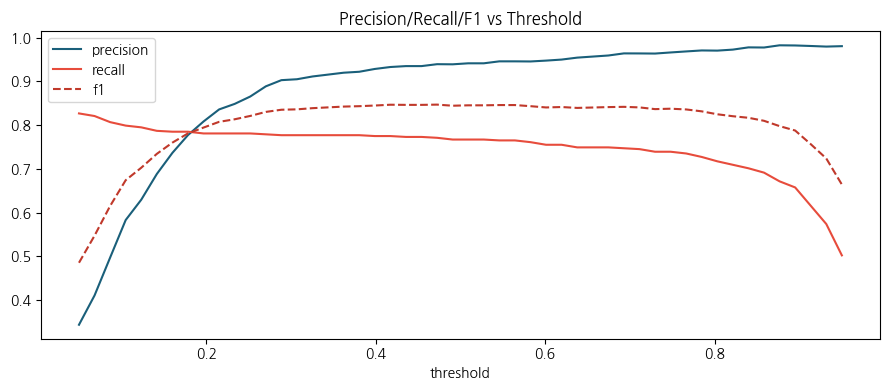

,threshold,precision,recall,f1,fp,fn
0,0.050000,0.343259,0.826693,0.485096,794,87
1,0.068367,0.410359,0.820717,0.547145,592,90
2,0.086735,0.496933,0.806773,0.615034,410,97
3,0.105102,0.582849,0.798805,0.673950,287,101
4,0.123469,0.629338,0.794821,0.702465,235,103


In [5]:
thresholds = np.linspace(0.05, 0.95, 50)
rows = []
for t in thresholds:
    pred_t = (valid_proba > t).astype(int)
    rows.append({
        'threshold': t,
        'precision': precision_score(y_valid.values, pred_t, zero_division=0),
        'recall':    recall_score(y_valid.values, pred_t, zero_division=0),
        'f1':        f1_score(y_valid.values, pred_t, zero_division=0),
        'fp':        int(((pred_t==1) & (y_valid.values==0)).sum()),
        'fn':        int(((pred_t==0) & (y_valid.values==1)).sum()),
    })
tune = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(tune['threshold'], tune['precision'], label='precision', color='#1a5f7a')
ax.plot(tune['threshold'], tune['recall'],    label='recall',    color='#e74c3c')
ax.plot(tune['threshold'], tune['f1'],        label='f1',        color='#c0392b', linestyle='--')
ax.set_xlabel('threshold'); ax.legend(); ax.set_title('Precision/Recall/F1 vs Threshold')
plt.tight_layout(); plt.show()
tune.head()

---
## Step 3. 시나리오별 최적 임계값

In [6]:
scenarios = pd.DataFrame([
    {'scenario':'high precision (자동 차단)', 'best': tune[tune['precision']>0.99].sort_values('recall', ascending=False).head(1)},
    {'scenario':'high recall (고가치 자산)',   'best': tune[tune['recall']   >0.95].sort_values('precision', ascending=False).head(1)},
    {'scenario':'best f1 (균형)',              'best': tune.sort_values('f1', ascending=False).head(1)},
])
for _, r in scenarios.iterrows():
    b = r['best'].iloc[0] if len(r['best'])>0 else None
    if b is not None:
        print(f"{r['scenario']}: t={b['threshold']:.3f}  P={b['precision']:.3f}  R={b['recall']:.3f}  F1={b['f1']:.3f}")

best f1 (균형): t=0.472  P=0.939  R=0.771  F1=0.847


비용비 FP:FN = 1:10 → 최적 threshold = 0.381 (FP=33, FN=112, 총비용=1153)


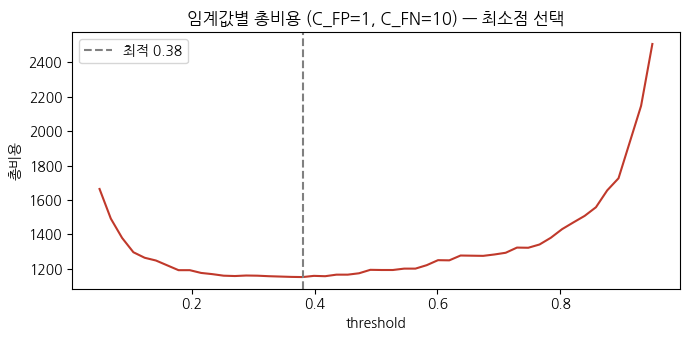

최종 테스트 F1: 0.8427672955974843


In [7]:
# 비용 기반 최적 임계값 — FP 와 FN 의 실제 비용이 다를 때 '총비용 최소'를 고른다.
C_FP, C_FN = 1, 10   # 오탐(FP)=1, 미탐(FN)=10 : 공격을 놓치는 비용이 10배
tune['cost'] = C_FP * tune['fp'] + C_FN * tune['fn']
best = tune.loc[tune['cost'].idxmin()]
print(f"비용비 FP:FN = 1:10 → 최적 threshold = {best['threshold']:.3f} "
      f"(FP={int(best['fp'])}, FN={int(best['fn'])}, 총비용={int(best['cost'])})")
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(tune['threshold'], tune['cost'], color='#c0392b')
ax.axvline(best['threshold'], ls='--', color='gray', label=f"최적 {best['threshold']:.2f}")
ax.set_title('임계값별 총비용 (C_FP=1, C_FN=10) — 최소점 선택')
ax.set_xlabel('threshold'); ax.set_ylabel('총비용'); ax.legend()
plt.tight_layout(); plt.show()
# 고정한 임계값으로 보류 테스트셋을 평가한다.
final_pred = (proba > float(best['threshold'])).astype(int)
print('최종 테스트 F1:', f1_score(y_te, final_pred))

---
## Step 4. 드리프트 모니터링 — KS 검정

In [8]:
# 운영 데이터: 분포가 약간 바뀐 신규 데이터
X_prod = pd.DataFrame({
    'log_dur':  np.log1p(rng.uniform(500, 800_000, size=3000)),     # mean 살짝 ↑
    'log_pkts': np.log1p(rng.integers(10, 200, size=3000)),        # mean 살짝 ↑
    'syn':      rng.uniform(0.05, 0.15, size=3000),                  # SYN 비율 ↑ (드리프트!)
})
for col in X_tr.columns:
    stat, p = ks_2samp(X_tr[col], X_prod[col])
    flag = '*** DRIFT' if p < 0.01 else 'OK'
    print(f'{col:10s}  KS={stat:.3f}  p={p:.4f}  {flag}')

# 출력 분포 드리프트
proba_tr = model.predict_proba(X_tr)[:,1].mean()
proba_pr = model.predict_proba(X_prod)[:,1].mean()
print(f'\n출력 평균 — train={proba_tr:.3f}, prod={proba_pr:.3f}, delta={abs(proba_pr-proba_tr):.3f}')

log_dur     KS=0.173  p=0.0000  *** DRIFT


log_pkts    KS=0.415  p=0.0000  *** DRIFT
syn         KS=0.806  p=0.0000  *** DRIFT

출력 평균 — train=0.157, prod=0.370, delta=0.213


---
## Step 5. 재학습 시뮬레이션

In [9]:
# 새 라벨 데이터 추가 (운영 분석가 피드백 시뮬레이션)
X_prod['y'] = rng.choice([0, 1], size=len(X_prod), p=[0.85, 0.15])
new_train = pd.concat([X_tr.assign(y=y_tr.values), X_prod], ignore_index=True)
X_new, y_new = new_train[['log_dur','log_pkts','syn']], new_train['y']
model2 = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1).fit(X_new, y_new)

# A/B 평가
auc_old = (model.predict_proba(X_te)[:,1] > 0.5).astype(int)
auc_new = (model2.predict_proba(X_te)[:,1] > 0.5).astype(int)
from sklearn.metrics import f1_score
print(f'F1 old = {f1_score(y_arr, auc_old):.3f}')
print(f'F1 new = {f1_score(y_arr, auc_new):.3f}')

F1 old = 0.850
F1 new = 0.849


---
## 적대적 머신러닝 — 회피 공격 데모
공격 샘플을 조금씩 변형해 탐지기가 '정상'으로 오분류하게 만든다(evasion). 방어: 적대적 훈련·입력 정규화·앙상블·모니터링. 표준 참조 MITRE ATLAS / OWASP ML Top 10.


In [10]:
import pandas as pd
cols = list(X_te.columns)
normal_mean = X_te[y_te.values == 0].mean().to_numpy()
cand = X_te[(y_te.values == 1) & (model.predict(X_te) == 1)]
orig = cand.iloc[0].to_numpy(); x = orig.copy(); alpha = 0.0
while model.predict(pd.DataFrame([x], columns=cols))[0] == 1 and alpha < 1.0:
    alpha += 0.02
    x = (1 - alpha) * orig + alpha * normal_mean   # 정상 중심 방향으로 최소 이동
flipped = model.predict(pd.DataFrame([x], columns=cols))[0] == 0
print(f'정상 방향 {alpha*100:.0f}% 이동 후 예측 = {"정상(회피 성공)" if flipped else "여전히 공격"}')
print('→ 의미는 공격이나 최소 변형으로 탐지기 우회. 방어: 적대적 훈련·입력 정규화·앙상블·HITL·모니터링')


정상 방향 40% 이동 후 예측 = 정상(회피 성공)
→ 의미는 공격이나 최소 변형으로 탐지기 우회. 방어: 적대적 훈련·입력 정규화·앙상블·HITL·모니터링


---
## 정리
- 임계값 50개 변화로 운영 시나리오에 맞추기가 즉시 가능.
- KS 검정으로 드리프트 자동 감지.
- 재학습 + A/B 비교가 운영 ML 의 표준 사이클.
- 다음 챕터 (ch17) 부터 LLM 으로 같은 로그를 자연어로 해석한다.